# Module 6 Lab 1: Query Like an Analyst

**CS 82A - Introduction to Data Science**

**Ramisha Tasfia**

**GitHub:** [https://github.com/ramishatasfia5156-commits/cs82a-coursework/blob/main/module6/module6_lab.ipynb](https://github.com/ramishatasfia5156-commits/cs82a-coursework/blob/main/module6/module6_lab.ipynb)

## Step 1: Load the CSVs and Build the Database

In [1]:
import sqlite3
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

orders_df = pd.read_csv("store_orders.csv")
customers_df = pd.read_csv("store_customers.csv")
print("orders:", orders_df.shape, "| customers:", customers_df.shape)

con = sqlite3.connect("store.db")
orders_df.to_sql("orders", con, index=False, if_exists="replace")
customers_df.to_sql("customers", con, index=False, if_exists="replace")

pd.read_sql("SELECT name FROM sqlite_master", con)

orders: (200, 6) | customers: (40, 4)


,name
0,orders
1,customers


## Step 2: First Look

In [2]:
pd.read_sql("SELECT * FROM orders LIMIT 5", con)

,order_id,customer_id,product,category,amount,order_date
0,5000,4,paper,office,14.09,2026-05-25
1,5001,15,planner,office,51.86,2026-05-08
2,5002,34,shelf,furniture,116.25,2026-06-03
3,5003,2,granola,snacks,19.72,2026-05-19
4,5004,17,monitor,electronics,284.80,2026-05-10


## Step 3: Filter and Sort

In [3]:
q3 = """
SELECT *
FROM orders
WHERE amount > 100
ORDER BY amount DESC
"""
big_orders = pd.read_sql(q3, con)
print("Orders over $100:", len(big_orders))
print("Smallest amount returned:", big_orders["amount"].min())
big_orders.head(10)

Orders over $100: 84
Smallest amount returned: 100.27


,order_id,customer_id,product,category,amount,order_date
0,5153,20,dock,electronics,499.00,2026-05-25
1,5140,30,headset,electronics,295.36,2026-05-26
2,5047,901,headset,electronics,293.79,2026-05-15
3,5150,903,monitor,electronics,293.35,2026-06-06
4,5014,6,monitor,electronics,287.83,2026-05-22
5,5113,4,headset,electronics,286.65,2026-05-15
6,5034,29,headset,electronics,286.36,2026-05-14
7,5149,8,headset,electronics,286.30,2026-05-05
8,5004,17,monitor,electronics,284.80,2026-05-10
9,5174,11,headset,electronics,277.24,2026-05-26


## Step 4: Aggregate by Category

In [4]:
q4 = """
SELECT category,
       COUNT(*)              AS n,
       ROUND(AVG(amount), 2) AS avg_amount
FROM orders
GROUP BY category
ORDER BY avg_amount DESC
"""
by_category = pd.read_sql(q4, con)
by_category

,category,n,avg_amount
0,electronics,60,190.57
1,furniture,46,146.25
2,office,51,30.13
3,snacks,43,14.62


Electronics earns the most per order, averaging $190.57 across 60 orders, compared with $14.62 for snacks.

## Step 5: Join for Spend by City

In [5]:
q5 = """
SELECT c.city,
       ROUND(SUM(o.amount), 2) AS total_spend
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
GROUP BY c.city
ORDER BY total_spend DESC
"""
spend_by_city = pd.read_sql(q5, con)
spend_by_city

,city,total_spend
0,Los Angeles,5862.99
1,Culver City,5316.88
2,Santa Monica,4017.93
3,Inglewood,2718.25
4,Torrance,1037.25
5,Venice,462.36


## Step 6: The Row-Count Audit

In [6]:
n_orders = pd.read_sql("SELECT COUNT(*) AS n FROM orders", con)["n"][0]

n_joined = pd.read_sql("""
SELECT COUNT(*) AS n
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
""", con)["n"][0]

print("Rows in orders:", n_orders)
print("Rows after the join:", n_joined)
print("Orders dropped by the join:", n_orders - n_joined)

# which orders have no matching customer
pd.read_sql("""
SELECT o.order_id, o.customer_id, o.amount
FROM orders o
LEFT JOIN customers c ON o.customer_id = c.customer_id
WHERE c.customer_id IS NULL
""", con)

Rows in orders: 200
Rows after the join: 195
Orders dropped by the join: 5


,order_id,customer_id,amount
0,5012,900,34.51
1,5047,901,293.79
2,5099,902,16.68
3,5150,903,293.35
4,5188,904,273.16


The orders table had 200 rows, however the join produced only 195. There are five order rows with Customer IDS of (900-904) which do not appear in the customers table. Therefore an inner join eliminates any row with no matching record. These five orders totaled ($911.49), therefore there is some under-reporting of the actual revenues for this location.

## Step 7: Chart a Query Result

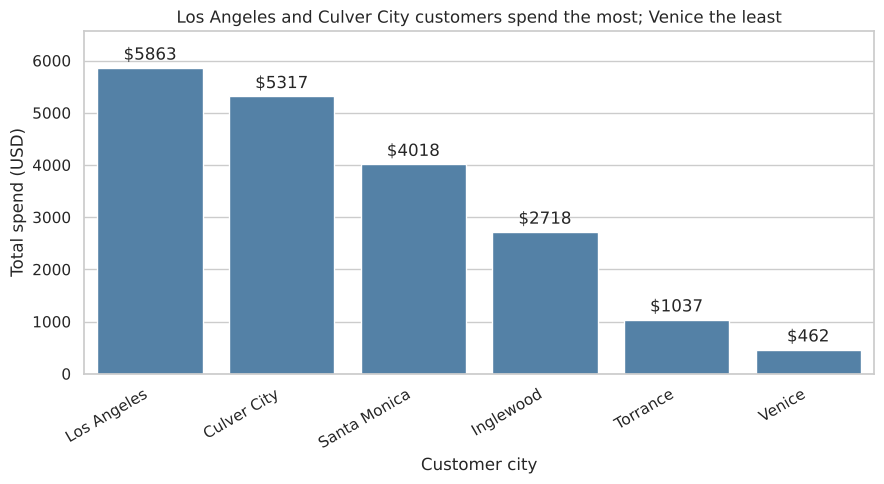

In [7]:
plt.figure(figsize=(9, 5))
ax = sns.barplot(data=spend_by_city, x="city", y="total_spend", color="steelblue")
ax.bar_label(ax.containers[0], fmt="$%.0f", padding=3)
plt.title("Los Angeles and Culver City customers spend the most; Venice the least")
plt.xlabel("Customer city")
plt.ylabel("Total spend (USD)")
plt.ylim(0, spend_by_city["total_spend"].max() * 1.12)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## Step 8: My Own Question

**Question:** Do customers who signed up earlier spend more per person than newer customers?

In [8]:
q8 = """
SELECT c.signup_year,
       COUNT(DISTINCT c.customer_id) AS customers,
       ROUND(SUM(o.amount) / COUNT(DISTINCT c.customer_id), 2) AS spend_per_customer
FROM customers c
JOIN orders o ON o.customer_id = c.customer_id
GROUP BY c.signup_year
ORDER BY spend_per_customer DESC
"""
pd.read_sql(q8, con)

,signup_year,customers,spend_per_customer
0,2021,8,654.84
1,2026,9,547.72
2,2023,5,538.59
3,2022,8,411.02
4,2024,5,410.90
5,2025,5,242.37


**Answer:** The data does not show a clear trend related to when each customer signed up for the business. Of all of the years examined, 2021 was the highest in terms of average amount spent per person ($654.84) while 2026 had an average amount spent per person that ranked 2nd ($547.72), with the lowest being 2025 customers who averaged only $242.37 in total amounts purchased. Therefore, it cannot be determined based on when a customer signs-up whether they will be a high or low spender.

## Step 9: Ethics Note and Safe Push

Prior to sharing publicly I would eliminate all customer names and customer ID's as they are the identifiers for an individual. Instead, I would create charts that show totals at the City Level or Cohort Level as opposed to totals by Customer ID. For example, I would have cities such as Venice combined in a different chart or left out of the data to be shared, because a city with so few customers could still point back to one specific person.

## AI Disclosure
Claude (Anthropic) was used to help explain concepts and draft the code for this lab. All code was reviewed and understood by me. Steps 6, 8, and 9 are my own work, as the lab requires.

Key prompt: "Help me with Module 6 Lab 1: Query Like an Analyst using the attached data."
